<a href="https://colab.research.google.com/github/sdow-docs/Data_Analytics/blob/main/Sarah_Colab_Works.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [43]:
### Start first by loading my libraries.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [44]:
### Load my dataset.
df = pd.read_csv('social_media_vs_productivity.csv')

In [45]:
### Inital look at the dataset.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             30000 non-null  int64  
 1   gender                          30000 non-null  object 
 2   job_type                        30000 non-null  object 
 3   daily_social_media_time         27235 non-null  float64
 4   social_platform_preference      30000 non-null  object 
 5   number_of_notifications         30000 non-null  int64  
 6   work_hours_per_day              30000 non-null  float64
 7   perceived_productivity_score    28386 non-null  float64
 8   actual_productivity_score       27635 non-null  float64
 9   stress_level                    28096 non-null  float64
 10  sleep_hours                     27402 non-null  float64
 11  screen_time_before_sleep        27789 non-null  float64
 12  breaks_during_work              

As this is a large datasset, I am going to remove all rows that are missing at least one value in a column. I am also going to look for and remove duplicate rows (if any).

In [46]:
df = df.dropna()

In [47]:
df.duplicated().sum()

np.int64(0)

In [48]:
### Did the cleanup help much?
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17074 entries, 0 to 29998
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             17074 non-null  int64  
 1   gender                          17074 non-null  object 
 2   job_type                        17074 non-null  object 
 3   daily_social_media_time         17074 non-null  float64
 4   social_platform_preference      17074 non-null  object 
 5   number_of_notifications         17074 non-null  int64  
 6   work_hours_per_day              17074 non-null  float64
 7   perceived_productivity_score    17074 non-null  float64
 8   actual_productivity_score       17074 non-null  float64
 9   stress_level                    17074 non-null  float64
 10  sleep_hours                     17074 non-null  float64
 11  screen_time_before_sleep        17074 non-null  float64
 12  breaks_during_work              17074

No duplicates were found. After removing rows containing at least one missing value, this is still a very large dataset. I want to only use a sample size of 5% for analysis and I want to make sure it is the same sample each time.

In [49]:
df = df.sample(frac=0.05, random_state=42)

In [50]:
## How big is the dataset now?
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 854 entries, 3661 to 16197
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             854 non-null    int64  
 1   gender                          854 non-null    object 
 2   job_type                        854 non-null    object 
 3   daily_social_media_time         854 non-null    float64
 4   social_platform_preference      854 non-null    object 
 5   number_of_notifications         854 non-null    int64  
 6   work_hours_per_day              854 non-null    float64
 7   perceived_productivity_score    854 non-null    float64
 8   actual_productivity_score       854 non-null    float64
 9   stress_level                    854 non-null    float64
 10  sleep_hours                     854 non-null    float64
 11  screen_time_before_sleep        854 non-null    float64
 12  breaks_during_work              854 

The sample size is now 854 rows and is a lot better to manage.

In [51]:
### Run descriptive statistics to better understand the dataset.
### For example, the minimum and maximum age will help me with createding age groups.
df.describe()

,age,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
count,854.000000,854.000000,854.000000,854.000000,854.000000,854.000000,854.000000,854.000000,854.000000,854.000000,854.000000,854.000000,854.000000,854.000000
mean,41.776347,3.214347,60.442623,6.989194,5.517646,4.933323,5.469555,6.498326,1.017053,5.052693,1.948478,15.930913,10.474655,4.927475
std,13.821093,2.203382,7.770800,1.986666,2.039795,1.914641,2.848810,1.460126,0.650146,3.226616,1.410783,9.199809,7.218914,2.130617
min,18.000000,0.000000,39.000000,0.000000,2.001756,0.713488,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,1.808446,56.000000,5.680571,3.661517,3.313862,3.000000,5.462022,0.532369,2.000000,1.000000,8.000000,4.671126,3.265969
50%,42.000000,3.078964,60.000000,6.956217,5.558436,4.911378,5.000000,6.491128,0.982382,5.000000,2.000000,16.000000,9.987798,5.044289
75%,53.000000,4.346789,65.000000,8.330446,7.311469,6.601171,8.000000,7.550985,1.455804,8.000000,3.000000,24.000000,15.424462,6.534930
max,65.000000,17.817948,89.000000,12.000000,8.998854,8.800745,10.000000,10.000000,3.000000,10.000000,6.000000,31.000000,36.359084,10.000000


In [52]:
### Next I want to define my chart colors to represent gender.
gender_colors = {
    'Male': '#3498DB',    # Blue
    'Female': '#E67EBD',  # Pink
    'Other': '#50C878'    # Green
}


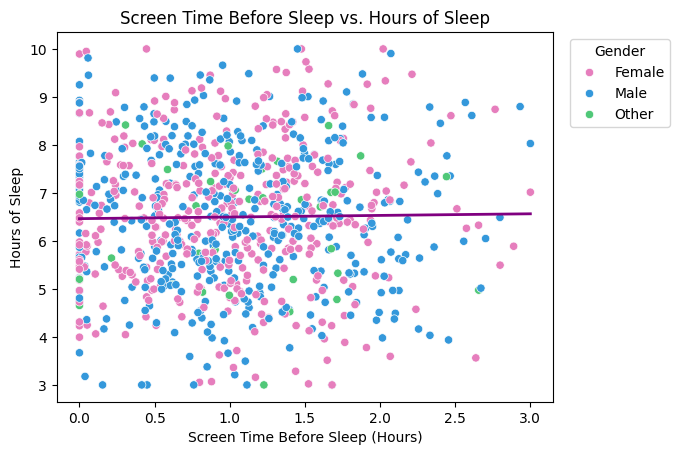

In [53]:
sns.scatterplot(
      data=df,
    x='screen_time_before_sleep',
    y='sleep_hours',hue='gender',palette=gender_colors)

sns.regplot(
    data=df,
    x='screen_time_before_sleep',
    y='sleep_hours',
    scatter=False,
    color='purple',ci=None,
    line_kws={'linewidth': 2}
)


plt.title('Screen Time Before Sleep vs. Hours of Sleep')
plt.xlabel('Screen Time Before Sleep (Hours)')
plt.ylabel('Hours of Sleep')
plt.legend(title='Gender', loc='upper left', bbox_to_anchor=(1.02, 1))

plt.show()

The trendline for the scatterplot is almost level. This would indicate that there is not a correlation between the screen time and amount of sleep. As only 5% of the database was sampled, this is not a definitive answer. I had rerun this with a 1.5% sampling and the trendline indicated a positive correlation. I think the dataset needed to be modified a bit more. For example to limit the sample to only one age range for the scatterplot.

In [54]:
## Create age groups
bins = [18, 25, 30, 35, 40, 45, 50, 55, 60, 65]
labels = ['18-24', '25-29', '30-34', '35-39',
          '40-44', '45-49', '50-54', '55-59', '60-65']

df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, include_lowest=True,
    right=True,)
df[['age', 'age_group']].head(20)

,age,age_group
3661,36,35-39
13279,21,18-24
29735,23,18-24
14700,36,35-39
7091,41,40-44
7137,38,35-39
1738,47,45-49
21709,18,18-24
8927,58,55-59
19381,33,30-34


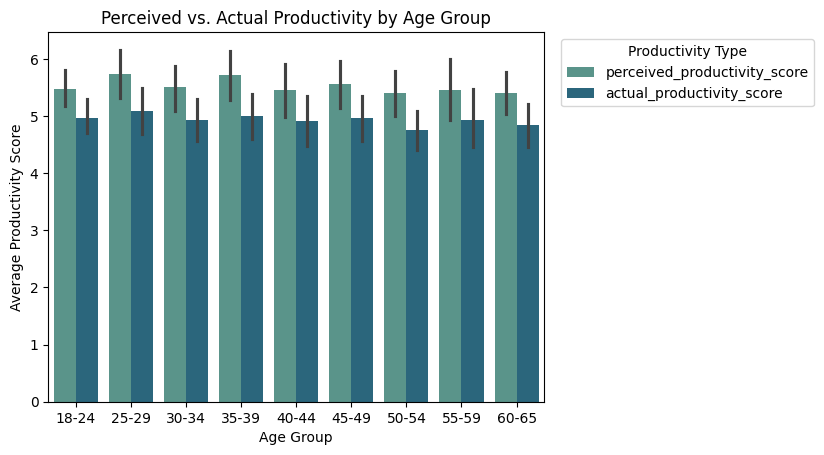

In [55]:
sns.color_palette("crest", as_cmap=True)
productivity_df = df.melt(
    id_vars='age_group',
    value_vars=[
        'perceived_productivity_score',
        'actual_productivity_score'
    ],
    var_name='productivity_type',
    value_name='productivity_score'
)
sns.barplot(
    data=productivity_df,
    x='age_group',
    y='productivity_score',
    hue='productivity_type',
    palette='crest'
)

plt.title('Perceived vs. Actual Productivity by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Productivity Score')
plt.legend(title='Productivity Type', loc='upper left', bbox_to_anchor=(1.02, 1))
plt.show()

This cart is very interesting. It appears that all age groups perceived they were more productive then they really were. This can hint that social media usage is taking more of their productivity time.

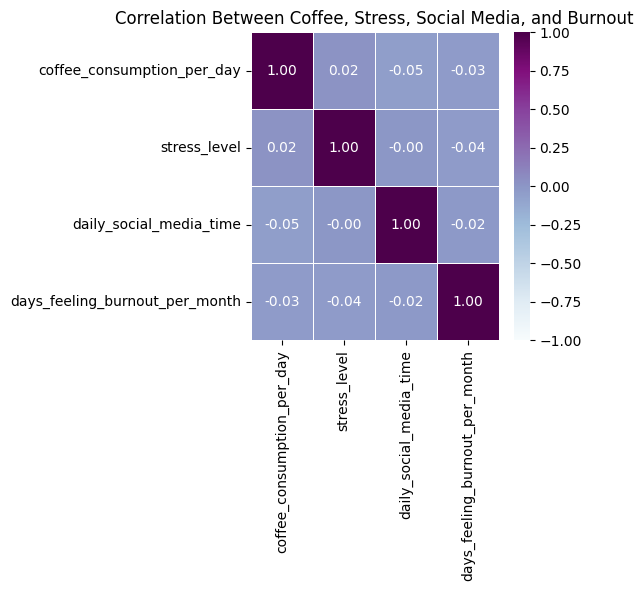

In [56]:
### Create a heatmap to determine correlations.

correlation = df[
    ['coffee_consumption_per_day','stress_level', 'daily_social_media_time', 'days_feeling_burnout_per_month']
].corr()

plt.figure(figsize=(4, 4))

sns.heatmap(
    correlation,
    annot=True,
    cmap='BuPu',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Correlation Between Coffee, Stress, Social Media, and Burnout')
plt.show()

This last chart also supprised me as daily social media seems to have no significant correlation to feeling burned out. It also has no linear correlation at all to stress level.